<a href="https://colab.research.google.com/github/ajaramillola1985/cauca-clima-gee/blob/main/06_aptitud_riesgo_cafe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aptitud para café y riesgo de roya y muerte descendente (Phoma) en el Cauca

Este notebook usa Google Earth Engine para generar tres mapas del departamento del Cauca:

1. **Zonas aptas para café** (análisis multicriterio de clima, suelo y relieve).
2. **Riesgo de roya** (*Hemileia vastatrix*).
3. **Riesgo de muerte descendente** (*Phoma* spp.).

Los umbrales y pesos están en la celda **Criterios**. Son valores de partida basados en publicaciones de Cenicafé y deben calibrarse con datos de campo.

## 1. Conexión a Earth Engine

In [15]:
import ee, geemap

import ee, geemap

PROYECTO_GEE = 'sig-unal-2026'

ee.Authenticate(auth_mode='notebook')
ee.Initialize(project=PROYECTO_GEE)

To authorize access needed by Earth Engine, open the following URL in a web browser and follow the instructions. If the web browser does not start automatically, please manually browse the URL below.

    https://code.earthengine.google.com/client-auth?scopes=https%3A//www.googleapis.com/auth/earthengine%20https%3A//www.googleapis.com/auth/cloud-platform%20https%3A//www.googleapis.com/auth/drive%20https%3A//www.googleapis.com/auth/devstorage.full_control&request_id=D9mtprSWfl3Crtl2xlgITbPZrmxdLY7OvVQrCrN1pmw&tc=qZaypIJrr12zMdCVVSRdPqV2Pv9Lfh8AwtKX4Lv_3u0&cc=gCTeZosclVmvJaoJsg7M6-NyhUf-Fz_nwbFjNg3Zfos

The authorization workflow will generate a code, which you should paste in the box below.
Enter verification code: 4/1AUn6Hd8UmbYLMT3GGJOiFJmdzvwWnczzae7E6egs8gswGtKe06rXljttPZI

Successfully saved authorization token.


## 2. Criterios (edita aquí umbrales y pesos)

- `trapecio: [a, b, c, d]`: puntaje 0 por debajo de `a`, sube a 1 en `b`, se mantiene hasta `c` y baja a 0 en `d`.
- `sube: [a, b]`: puntaje 0 en `a` o menos, 1 en `b` o más.
- `baja: [a, b]`: puntaje 1 en `a` o menos, 0 en `b` o más.
- Los pesos de cada mapa deben sumar 1.

In [48]:
PERIODO = ('2015-01-01', '2025-01-01')   # periodo para lluvia, humedad y viento

APTITUD_CAFE = {
    'temperatura': {'trapecio': [16, 18, 22, 24],         'peso': 0.30},  # °C, media anual
    'lluvia':      {'trapecio': [1200, 1500, 2800, 3500], 'peso': 0.20},  # mm/año
    'altitud':     {'trapecio': [1000, 1300, 1900, 2200], 'peso': 0.15},  # m
    'pendiente':   {'baja':     [50, 100],                'peso': 0.15},  # %
    'ph':          {'trapecio': [4.5, 5.0, 5.5, 6.5],     'peso': 0.20},  # pH del suelo
}

RIESGO_ROYA = {
    'temperatura': {'trapecio': [15, 21, 25, 28], 'peso': 0.45},  # °C
    'altitud':     {'baja':     [1300, 2000],     'peso': 0.30},  # m
    'lluvia':      {'sube':     [1500, 2500],     'peso': 0.15},  # mm/año
    'humedad':     {'sube':     [78, 92],         'peso': 0.10},  # %
}

RIESGO_PHOMA = {
    'altitud':     {'sube': [1400, 1900], 'peso': 0.35},  # m
    'temperatura': {'baja': [17, 21],     'peso': 0.25},  # °C
    'amplitud':    {'sube': [9.5, 11.5],  'peso': 0.20},  # °C día-noche
    'lluvia':      {'sube': [1800, 3200], 'peso': 0.20},  # mm/año
}

# Clases de ESA WorldCover que se excluyen: construido, nieve, agua, humedal, manglar
COBERTURAS_EXCLUIDAS = [50, 70, 80, 90, 95]
EXCLUIR_AREAS_PROTEGIDAS = False

for nombre, crit in [('aptitud', APTITUD_CAFE), ('roya', RIESGO_ROYA), ('phoma', RIESGO_PHOMA)]:
    total = sum(v['peso'] for v in crit.values())
    assert abs(total - 1) < 1e-6, f'Los pesos de {nombre} suman {total}, deben sumar 1'

## 3. Área de estudio

In [49]:
cauca = (ee.FeatureCollection('FAO/GAUL/2015/level1')
         .filter(ee.Filter.eq('ADM0_NAME', 'Colombia'))
         .filter(ee.Filter.eq('ADM1_NAME', 'Cauca')))   # nombre exacto: excluye Valle del Cauca
region = cauca.geometry()
print('Departamentos encontrados:', cauca.size().getInfo())   # debe ser 1

Departamentos encontrados: 1


## 4. Capas de clima, suelo y relieve

In [50]:
import math

# Relieve (SRTM, 30 m)
dem = ee.Image('USGS/SRTMGL1_003')
altitud = dem.rename('altitud')
pendiente = (ee.Terrain.slope(dem).multiply(math.pi / 180).tan()
             .multiply(100).rename('pendiente'))            # en %

# Climatología WorldClim (1 km): temperatura media y amplitud térmica diaria
bio = ee.Image('WORLDCLIM/V1/BIO')
temperatura = bio.select('bio01').multiply(0.1).rename('temperatura')   # °C
amplitud = bio.select('bio02').multiply(0.1).rename('amplitud')         # °C

# Lluvia anual media (CHIRPS)
anios = ee.Number(ee.Date(PERIODO[1]).difference(ee.Date(PERIODO[0]), 'year'))
lluvia = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
          .filterDate(*PERIODO)
          .map(lambda img: img.resample('bilinear'))
          .sum().divide(anios).rename('lluvia'))

# Humedad relativa y viento (ERA5-Land mensual, ~11 km)
era = (ee.ImageCollection('ECMWF/ERA5_LAND/MONTHLY_AGGR')
       .filterDate(*PERIODO).mean())
t = era.select('temperature_2m').subtract(273.15)
td = era.select('dewpoint_temperature_2m').subtract(273.15)
def presion_vapor(x):
    return x.multiply(17.625).divide(x.add(243.04)).exp()
humedad = presion_vapor(td).divide(presion_vapor(t)).multiply(100).rename('humedad')  # %
viento = (era.select('u_component_of_wind_10m').pow(2)
          .add(era.select('v_component_of_wind_10m').pow(2)).sqrt().rename('viento'))  # m/s

# pH del suelo en superficie (OpenLandMap, 250 m)
ph = (ee.Image('OpenLandMap/SOL/SOL_PH-H2O_USDA-4C1A2A_M/v02')
      .select('b0').multiply(0.1).rename('ph'))

# Cobertura del suelo (ESA WorldCover, 10 m)
cobertura = ee.ImageCollection('ESA/WorldCover/v200').first().rename('cobertura')

capas = (ee.Image.cat([altitud, pendiente, temperatura, amplitud,
                       lluvia, humedad, viento, ph]).clip(region))
print(capas.bandNames().getInfo())

['altitud', 'pendiente', 'temperatura', 'amplitud', 'lluvia', 'humedad', 'viento', 'ph']


## 5. Funciones de puntaje

In [51]:
def puntaje(img, regla):
    """Convierte una capa a un puntaje de 0 a 1 según la regla del criterio."""
    if 'trapecio' in regla:
        a, b, c, d = regla['trapecio']
        sube = img.subtract(a).divide(b - a)
        baja = ee.Image.constant(d).subtract(img).divide(d - c)
        return sube.min(baja).clamp(0, 1)
    if 'sube' in regla:
        a, b = regla['sube']
        return img.subtract(a).divide(b - a).clamp(0, 1)
    if 'baja' in regla:
        a, b = regla['baja']
        return ee.Image.constant(b).subtract(img).divide(b - a).clamp(0, 1)
    raise ValueError(f'Regla no reconocida: {regla}')

def indice(criterios, nombre):
    """Suma ponderada de los puntajes de cada variable (resultado de 0 a 1)."""
    total = ee.Image.constant(0)
    for variable, regla in criterios.items():
        total = total.add(puntaje(capas.select(variable), regla).multiply(regla['peso']))
    return total.rename(nombre).clip(region)

def clasificar(img):
    """Clases 1 a 5 con cortes en 0,2 / 0,4 / 0,6 / 0,8."""
    return (img.gte(0.2).add(img.gte(0.4)).add(img.gte(0.6)).add(img.gte(0.8))
            .add(1).rename('clase').updateMask(img.mask()))

## 6. Restricciones

In [52]:
permitido = cobertura.remap(COBERTURAS_EXCLUIDAS, [0] * len(COBERTURAS_EXCLUIDAS), 1)

if EXCLUIR_AREAS_PROTEGIDAS:
    protegidas = (ee.FeatureCollection('WCMC/WDPA/current/polygons')
                  .filterBounds(region))
    mascara_protegidas = ee.Image.constant(1).paint(protegidas, 0)
    permitido = permitido.And(mascara_protegidas)

permitido = permitido.clip(region)

## 7. Mapa de zonas aptas para café

In [62]:
aptitud = indice(APTITUD_CAFE, 'aptitud').updateMask(permitido)
aptitud_clase = clasificar(aptitud)

PALETA_APT = ['#d7191c', '#fdae61', '#ffffbf', '#a6d96a', '#1a9641']
ETIQ_APT = ['No apto', 'Marginal', 'Moderado', 'Apto', 'Muy apto']

from ipyleaflet import basemaps

m = geemap.Map(basemap=basemaps.Esri.WorldTopoMap)
m.centerObject(cauca, 8)
m.addLayer(aptitud_clase, {'min': 1, 'max': 5, 'palette': PALETA_APT}, 'Aptitud café')
m.addLayer(cauca.style(color='black', fillColor='00000000'), {}, 'Cauca')
m.add_legend(title='Aptitud para café', legend_dict=dict(zip(ETIQ_APT, PALETA_APT)))
m
excluido = permitido.Not().selfMask()
m.addLayer(excluido, {'palette': ['#9e9e9e']}, 'Excluido por restricción')
m.addLayer(municipios.style(color='#555555', fillColor='00000000', width=1), {}, 'Municipios')
m.addLayer(protegidas.style(color='#4a148c', fillColor='00000000', width=1),
           {}, 'Áreas protegidas')

## 8. Mapas de riesgo de roya y de Phoma

El riesgo se muestra solo donde la aptitud para café es al menos marginal (índice ≥ 0,2).

In [54]:
alt = capas.select('altitud')
zona_cafe = aptitud.gte(0.4).And(alt.gte(1000)).And(alt.lte(2200))

roya = indice(RIESGO_ROYA, 'riesgo_roya').updateMask(zona_cafe)
phoma = indice(RIESGO_PHOMA, 'riesgo_phoma').updateMask(zona_cafe)
roya_clase = clasificar(roya)
phoma_clase = clasificar(phoma)

PALETA_RIESGO = ['#1a9641', '#a6d96a', '#ffffbf', '#fdae61', '#d7191c']
ETIQ_RIESGO = ['Muy bajo', 'Bajo', 'Medio', 'Alto', 'Muy alto']
vis = {'min': 1, 'max': 5, 'palette': PALETA_RIESGO}
borde = cauca.style(color='black', fillColor='00000000')

roya = indice(RIESGO_ROYA, 'riesgo_roya').updateMask(zona_cafe)
phoma = indice(RIESGO_PHOMA, 'riesgo_phoma').updateMask(zona_cafe)
roya_clase = clasificar(roya)
phoma_clase = clasificar(phoma)

PALETA_RIESGO = ['#1a9641', '#a6d96a', '#ffffbf', '#fdae61', '#d7191c']
ETIQ_RIESGO = ['Muy bajo', 'Bajo', 'Medio', 'Alto', 'Muy alto']
vis = {'min': 1, 'max': 5, 'palette': PALETA_RIESGO}

m2 = geemap.Map(basemap=basemaps.Esri.WorldTopoMap)
m2.centerObject(cauca, 8)
m2.addLayer(roya_clase, vis, 'Riesgo de roya')
m2.addLayer(phoma_clase, vis, 'Riesgo de Phoma', False)   # actívala en el control de capas
m2.addLayer(cauca.style(color='black', fillColor='00000000'), {}, 'Cauca')
m2.add_legend(title='Riesgo', legend_dict=dict(zip(ETIQ_RIESGO, PALETA_RIESGO)))
m2

Map(center=[2.386404757557793, -76.85773600586428], controls=(WidgetControl(options=['position', 'transparent_…

In [55]:
import pandas as pd

stats = capas.updateMask(zona_cafe).reduceRegion(
    reducer=ee.Reducer.percentile([5, 25, 50, 75, 95]),
    geometry=region, scale=250, maxPixels=1e10, tileScale=4).getInfo()

filas = {}
for clave, valor in stats.items():
    variable, p = clave.rsplit('_', 1)
    filas.setdefault(variable, {})[p] = round(valor, 1)

display(pd.DataFrame(filas).T[['p5', 'p25', 'p50', 'p75', 'p95']])

,p5,p25,p50,p75,p95
altitud,1043.5,1307.5,1619.5,1843.4,2123.5
amplitud,9.9,10.4,11.0,11.2,11.5
humedad,77.8,81.6,86.2,89.8,91.9
lluvia,1607.6,1944.2,2264.0,2616.1,3559.9
pendiente,2.5,12.5,24.5,37.5,56.5
ph,5.0,5.2,5.3,5.5,5.7
temperatura,16.3,17.8,19.3,21.2,23.1
viento,0.1,0.3,0.4,0.5,0.8


Mapa de riesgo de roya

In [56]:
m_roya = geemap.Map(basemap=basemaps.Esri.WorldTopoMap)
m_roya.centerObject(cauca, 8)
m_roya.addLayer(roya_clase, vis, 'Riesgo de roya')
m_roya.addLayer(borde, {}, 'Cauca')
m_roya.add_legend(title='Riesgo de roya', legend_dict=dict(zip(ETIQ_RIESGO, PALETA_RIESGO)))
m_roya

Map(center=[2.3864047575577896, -76.85773600586428], controls=(WidgetControl(options=['position', 'transparent…

municipios, zonas no aptas

In [59]:
# División política municipal (FAO GAUL nivel 2)
municipios = (ee.FeatureCollection('FAO/GAUL/2015/level2')
              .filter(ee.Filter.eq('ADM0_NAME', 'Colombia'))
              .filter(ee.Filter.eq('ADM1_NAME', 'Cauca')))
print('Municipios:', municipios.size().getInfo())

# Todo lo que queda fuera de la zona cafetera, dentro del Cauca
no_apto = zona_cafe.unmask(0).Not().selfMask().clip(region)

COLOR_NO_APTO = '#d9d9d9'   # gris suave; prueba '#efe6d5' para un beige

def mapa_riesgo(clase, titulo):
    m = geemap.Map(basemap=basemaps.Esri.WorldTopoMap)
    m.centerObject(cauca, 8)
    m.addLayer(no_apto, {'palette': [COLOR_NO_APTO]}, 'No apto para café', True, 0.75)
    m.addLayer(clase, vis, titulo)
    m.addLayer(municipios.style(color='#555555', fillColor='00000000', width=1), {}, 'Municipios')
    m.addLayer(cauca.style(color='black', fillColor='00000000', width=2), {}, 'Cauca')
    leyenda = dict(zip(ETIQ_RIESGO, PALETA_RIESGO))
    leyenda['No apto para café'] = COLOR_NO_APTO
    m.add_legend(title=titulo, legend_dict=leyenda)
    return m

Municipios: 40


In [60]:
mapa_riesgo(roya_clase, 'Riesgo de roya')

Map(center=[2.3864047575577896, -76.85773600586428], controls=(WidgetControl(options=['position', 'transparent…

In [61]:
mapa_riesgo(phoma_clase, 'Riesgo de Phoma')

Map(center=[2.386404757557793, -76.85773600586428], controls=(WidgetControl(options=['position', 'transparent_…

Mapa de riesgo de Phoma

In [57]:
m_phoma = geemap.Map(basemap=basemaps.Esri.WorldTopoMap)
m_phoma.centerObject(cauca, 8)
m_phoma.addLayer(phoma_clase, vis, 'Riesgo de Phoma')
m_phoma.addLayer(borde, {}, 'Cauca')
m_phoma.add_legend(title='Riesgo de Phoma', legend_dict=dict(zip(ETIQ_RIESGO, PALETA_RIESGO)))
m_phoma

Map(center=[2.3864047575577896, -76.85773600586428], controls=(WidgetControl(options=['position', 'transparent…

## 9. Área por clase (hectáreas)

In [58]:
import pandas as pd

def area_por_clase(clase, etiquetas, escala=100):
    img = ee.Image.pixelArea().divide(10000).addBands(clase)
    res = img.reduceRegion(
        reducer=ee.Reducer.sum().group(groupField=1, groupName='clase'),
        geometry=region, scale=escala, maxPixels=1e10, tileScale=4).getInfo()
    filas = [{'clase': etiquetas[int(g['clase']) - 1], 'hectareas': round(g['sum'])}
             for g in res['groups']]
    return pd.DataFrame(filas)

print('Aptitud para café');  display(area_por_clase(aptitud_clase, ETIQ_APT))
print('Riesgo de roya');     display(area_por_clase(roya_clase, ETIQ_RIESGO))
print('Riesgo de Phoma');    display(area_por_clase(phoma_clase, ETIQ_RIESGO))

Aptitud para café


,clase,hectareas
0,No apto,104651
1,Marginal,591867
2,Moderado,1061976
3,Apto,322184
4,Muy apto,773456


Riesgo de roya


,clase,hectareas
0,Muy bajo,42990
1,Bajo,185581
2,Medio,261411
3,Alto,264003
4,Muy alto,361992


Riesgo de Phoma


,clase,hectareas
0,Muy bajo,116789
1,Bajo,368049
2,Medio,209226
3,Alto,332973
4,Muy alto,88939


Autenticar

In [74]:
ee.Authenticate(auth_mode='notebook', force=True)
ee.Initialize(project=PROYECTO_GEE)

To authorize access needed by Earth Engine, open the following URL in a web browser and follow the instructions. If the web browser does not start automatically, please manually browse the URL below.

    https://code.earthengine.google.com/client-auth?scopes=https%3A//www.googleapis.com/auth/earthengine%20https%3A//www.googleapis.com/auth/cloud-platform%20https%3A//www.googleapis.com/auth/drive%20https%3A//www.googleapis.com/auth/devstorage.full_control&request_id=GybjAHP6Om8gG_J8BqbIqgc96cYaNSafBAjyu3QKNw8&tc=VgBam5LRJ7mu3IRiMWRb5QFqa64oLzMtDi2I7ItpY7o&cc=4OjBKUkvhTjfn8Daa__I7MRlSeYVxV1PzQNUI6FuGY8

The authorization workflow will generate a code, which you should paste in the box below.
Enter verification code: 4/1AUn6Hd_aPDXEWEj22r-zDpqhTVoJ1p2oQofNAEsY0OWKu6Woh9OTIkNPu6Y

Successfully saved authorization token.


Descarga directa desde colab en .tif para qgis

In [75]:
!pip install -q rasterio
import zipfile
import numpy as np, rasterio
from google.colab import files

# Se suma 1: los valores reales quedan entre 1 y 2, y el 0 queda solo para "sin dato"
origen = 'cauca_cafe_v2.tif'
salida = ee.Image.cat([aptitud, roya, phoma]).toFloat().unmask(-1).add(1)
geemap.ee_export_image(salida, filename=origen, scale=250,
                       region=region, crs='EPSG:4326')

VERDE_A_ROJO = ['#1a9641', '#a6d96a', '#ffffbf', '#fdae61', '#d7191c']
mapas = [('aptitud_cafe', VERDE_A_ROJO[::-1]),
         ('riesgo_roya',  VERDE_A_ROJO),
         ('riesgo_phoma', VERDE_A_ROJO)]

def rgba(h):
    h = h.lstrip('#')
    return (int(h[0:2], 16), int(h[2:4], 16), int(h[4:6], 16), 255)

with rasterio.open(origen) as src:
    perfil = src.profile.copy()
    perfil.update(count=1, dtype='uint8', nodata=0, compress='lzw')
    for banda, (nombre, paleta) in enumerate(mapas, start=1):
        v = src.read(banda)
        ok = v >= 1
        x = v[ok] - 1
        clase = np.zeros(v.shape, dtype='uint8')
        clase[ok] = 1 + (x >= 0.2) + (x >= 0.4) + (x >= 0.6) + (x >= 0.8)
        colores = {0: (0, 0, 0, 0)}
        colores.update({i + 1: rgba(c) for i, c in enumerate(paleta)})
        with rasterio.open(nombre + '.tif', 'w', **perfil) as dst:
            dst.write(clase, 1)
            dst.write_colormap(1, colores)
        print(nombre, '- sin dato:', round(100 * (~ok).mean()), '%')

with zipfile.ZipFile('mapas_cafe_cauca.zip', 'w') as z:
    for nombre, _ in mapas:
        z.write(nombre + '.tif')

files.download('mapas_cafe_cauca.zip')

Generating URL ...
Please wait ...
Data downloaded to /content/cauca_cafe_v2.tif
aptitud_cafe - sin dato: 59 %
riesgo_roya - sin dato: 84 %
riesgo_phoma - sin dato: 84 %


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descargar imagenes .png

In [77]:
import rasterio, numpy as np, matplotlib.pyplot as plt
from google.colab import files

with rasterio.open("/content/cauca_cafe_v2.tif") as src:
    nombres = [d or f"banda_{i}" for i, d in enumerate(src.descriptions, 1)]
    extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]
    for i, nombre in enumerate(nombres, 1):
        a = src.read(i, masked=True)
        fig, ax = plt.subplots(figsize=(8, 8))
        im = ax.imshow(a, extent=extent, cmap="RdYlGn" if "aptitud" in nombre else "YlOrRd")
        fig.colorbar(im, ax=ax, shrink=0.7, label=nombre)
        ax.set_title(nombre); ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
        salida = f"/content/{nombre}.png"
        fig.savefig(salida, dpi=200, bbox_inches="tight"); plt.close(fig)
        print(f"✔ {salida}")
        files.download(salida)   # descarga directa a tu computador

✔ /content/banda_1.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✔ /content/banda_2.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✔ /content/banda_3.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✔ 42 municipios de Cauca
banda_1: sin dato DENTRO del Cauca = 11 %


ValueError: aspect must be finite and positive 

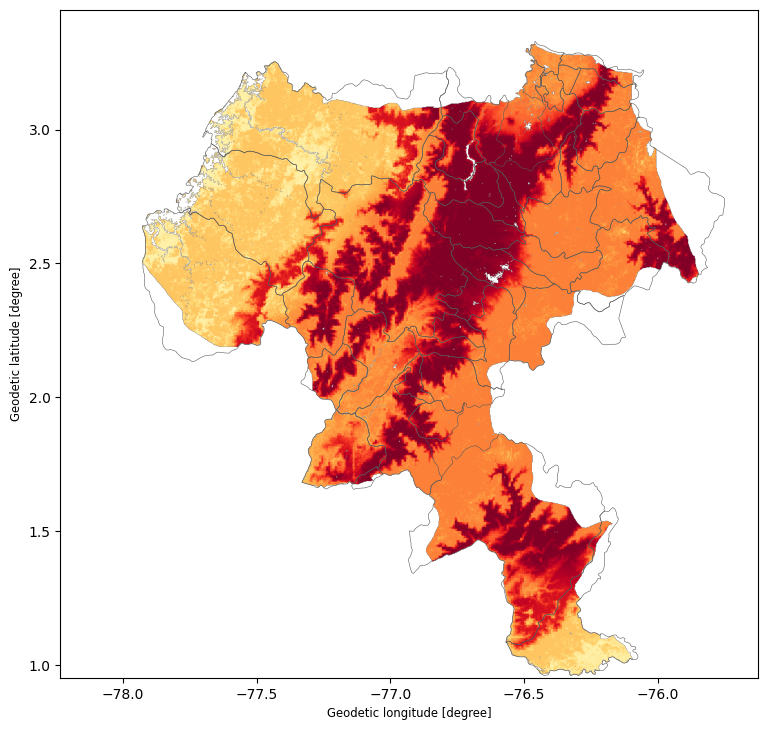

In [78]:
import ee, geemap, rasterio, numpy as np, matplotlib.pyplot as plt
from rasterio.features import geometry_mask
from google.colab import files

# --- 1) Límites desde Earth Engine (FAO GAUL 2025) ---
DEPTO = "Cauca"
muni_fc = (ee.FeatureCollection("FAO/GAUL/2025/level2")
           .filter(ee.Filter.eq("ISO3_CODE", "COL"))
           .filter(ee.Filter.eq("GAUL1_NAME", DEPTO))
           .map(lambda f: f.simplify(maxError=50)))
municipios = geemap.ee_to_gdf(muni_fc).set_crs("EPSG:4326", allow_override=True)
depto = municipios.dissolve()                     # contorno del departamento
print(f"✔ {len(municipios)} municipios de {DEPTO}")

# --- 2) Mapas con límites ---
with rasterio.open("/content/cauca_cafe_v2.tif") as src:
    municipios = municipios.to_crs(src.crs); depto = depto.to_crs(src.crs)
    fuera = geometry_mask(depto.geometry, out_shape=(src.height, src.width),
                          transform=src.transform)            # True = fuera del Cauca
    extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]
    nombres = [d or f"banda_{i}" for i, d in enumerate(src.descriptions, 1)]

    for i, nombre in enumerate(nombres, 1):
        a = src.read(i, masked=True)
        a = np.ma.masked_where(fuera | np.ma.getmaskarray(a), a)
        dentro = ~fuera
        sin_dato = np.ma.getmaskarray(a)[dentro].mean() * 100
        print(f"{nombre}: sin dato DENTRO del Cauca = {sin_dato:.0f} %")

        fig, ax = plt.subplots(figsize=(9, 9))
        im = ax.imshow(a, extent=extent, cmap="RdYlGn" if "aptitud" in nombre else "YlOrRd")
        municipios.boundary.plot(ax=ax, color="0.35", linewidth=0.4)   # límites municipales
        depto.boundary.plot(ax=ax, color="black", linewidth=1.2)       # límite departamental
        b = depto.total_bounds
        ax.set_xlim(b[0], b[2]); ax.set_ylim(b[1], b[3])
        fig.colorbar(im, ax=ax, shrink=0.6, label=nombre)
        ax.set_title(f"{nombre} – {DEPTO}"); ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")

        salida = f"/content/{nombre}_{DEPTO}.png"
        fig.savefig(salida, dpi=250, bbox_inches="tight"); plt.close(fig)
        files.download(salida)

# --- 3) (Opcional) Límites como archivo para QGIS ---
municipios.to_crs("EPSG:4326").to_file("/content/municipios_cauca.gpkg", driver="GPKG")
files.download("/content/municipios_cauca.gpkg")

In [ ]:
from google.colab import files

salida = ee.Image.cat([aptitud, roya, phoma]).toFloat().unmask(-1)
archivo = 'cauca_cafe_aptitud_riesgo.tif'

geemap.ee_export_image(salida, filename=archivo, scale=250,
                       region=region, crs='EPSG:4326')
files.download(archivo)

## 10. Exportar a Google Drive (GeoTIFF)

In [ ]:
salida = ee.Image.cat([aptitud, roya, phoma]).toFloat()

tarea = ee.batch.Export.image.toDrive(
    image=salida, description='cauca_cafe_aptitud_riesgo',
    folder='cauca_gee', region=region, scale=100, crs='EPSG:4326', maxPixels=1e10)
tarea.start()
print('Exportación iniciada. Revisa el avance en https://code.earthengine.google.com/tasks')